# Практика · ML Handbook гл. 37 (regularization)

Источник: [dl-regularization](https://mlhandbook-production.up.railway.app/parts/deep-learning/dl-regularization.html)

Теория: [d.4.37 … .md](../d.4.37%20Регуляризация%20в%20DL/d.4.37%20Регуляризация%20в%20DL.md) · [README.md](./README.md)

**Handbook-код — в этом файле**. Эталон: [handbook_gl37_практика_решения.ipynb](./handbook_gl37_практика_решения.ipynb) **после** попытки. Deep-ML: [deep_ml/](./deep_ml/README.md).

| ☐ | Блок |
|---|------|
| ☐ | §37.2 Dropout train/eval |
| ☐ | §37.7 dropout vs overfit |
| ☐ | MLP + BN + Dropout |
| ☐ | NumPy ↔ torch сверка |


# §37.2 · Dropout: `train()` vs `eval()`

Как на сайте: выходы **разные** (в eval dropout выключен).

In [1]:
import torch
from torch import nn

net = nn.Sequential(nn.Linear(100, 64), nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, 10))
x = torch.randn(4, 100)
net.train()
out_train = net(x)
net.eval()
out_eval = net(x)
print("train и eval разные:", not torch.allclose(out_train, out_eval))

train и eval разные: True


---


# §37.7 · Dropout vs переобучение

Маленький датасет: сравни train/test loss **с** `Dropout(0.5)` и **без** (как на сайте — разрыв меньше с dropout).

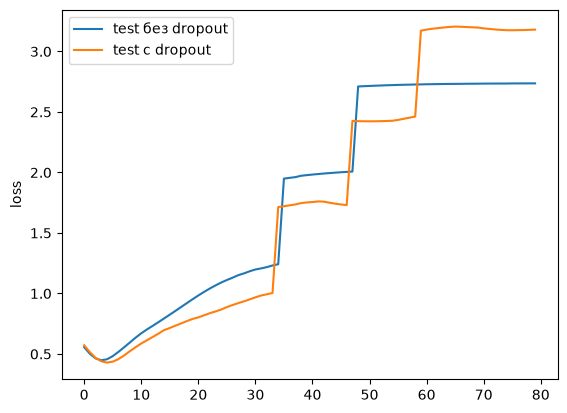

In [6]:
import matplotlib.pyplot as plt


def fit_with_dropout(use_dropout: bool):
    torch.manual_seed(0)
    X = torch.randn(48, 8)
    y = (X[:, :3].sum(dim=1) > 0).float().unsqueeze(1)
    Xt = torch.randn(120, 8)
    yt = (Xt[:, :3].sum(dim=1) > 0).float().unsqueeze(1)

    layers = [nn.Linear(8, 32), nn.ReLU()]
    if use_dropout:
        layers += [nn.Dropout(0.5)]
    layers += [nn.Linear(32, 1), nn.Sigmoid()]
    model = nn.Sequential(*layers)
    opt = torch.optim.Adam(model.parameters(), lr=0.05)
    lossf = nn.BCELoss()
    tr, te = [], []
    for _ in range(80):
        model.train()
        opt.zero_grad()
        lt = lossf(model(X), y)
        lt.backward()
        opt.step()
        tr.append(float(lt.item()))
        model.eval()
        with torch.no_grad():
            te.append(float(lossf(model(Xt), yt).item()))
    return tr, te


tr0, te0 = fit_with_dropout(False)
tr1, te1 = fit_with_dropout(True)
plt.plot(te0, label="test без dropout")
plt.plot(te1, label="test с dropout")
plt.legend()
plt.ylabel("loss")
plt.show()

---


# Lab · MLP с регуляризацией

Блок: `Linear` → `BatchNorm1d` → `ReLU` → `Dropout` (ментор / PyTorch Basics). Обучи на синтетике; `train()` / `eval()` на инференсе.

In [22]:
import torch
from torch import nn


class RegularizedMLP(nn.Module):
    def __init__(self, in_dim=20, hidden=32, out_dim=2, p_drop=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(hidden, out_dim),
        )

    def forward(self, x):
        return self.net(x)


torch.manual_seed(0)
X = torch.randn(64, 20)
y = torch.randint(0, 2, (64,))
model = RegularizedMLP()
opt = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay=1e-3)
lossf = nn.CrossEntropyLoss()
for _ in range(30):
    model.train()
    opt.zero_grad()
    lossf(model(X), y).backward()
    opt.step()
model.eval()
with torch.no_grad():
    acc = (model(X).argmax(1) == y).float().mean()
print(model)
print("train acc (demo):", float(acc))

RegularizedMLP(
  (net): Sequential(
    (0): Linear(in_features=20, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)
train acc (demo): 1.0


---


# Сверка NumPy ↔ torch

После `deep_ml/`: один батч — **среднее** после inverted dropout (train) совпадает с входом; BN eval — твой `bn_eval` vs `nn.BatchNorm1d` в `.eval()`.

In [21]:
import numpy as np
import torch
from torch import nn


def need(cond, msg=""):
    assert cond, msg


def dropout_numpy(x, p=0.5, training=True):
    if not training:
        return x
    mask = (np.random.rand(*x.shape) > p).astype(float)
    return x * mask / (1.0 - p)


np.random.seed(0)
x = np.ones((32, 8))
y = dropout_numpy(x, training=True)
need(abs(x.mean() - y.mean()) < 0.2)

torch.manual_seed(0)
bn = nn.BatchNorm1d(8)
bn.train()
for _ in range(5):
    _ = bn(torch.randn(16, 8))
bn.eval()
xt = torch.randn(4, 8)
torch_out = bn(xt)
mu = bn.running_mean
var = bn.running_var
manual = (xt - mu) / torch.sqrt(var + bn.eps) * bn.weight + bn.bias
need(torch.allclose(torch_out, manual, atol=1e-5))
print("dropout mean ok, BN eval ok")


dropout mean ok, BN eval ok
